# A Tour of the Rubin Alert Archive Schema

This notebook looks at a small piece of the Rubin alert archive HATS catalog to show what is in it:
the top-level and nested columns, what one row (one alert) contains, and how the history columns
(`prvDiaSources`, `prvDiaForcedSources`) relate to the alert's own detection (`diaSource`).

It reads a single partition, so it runs in well under a minute. It was executed on the USDF
(`/sdf/data/...` paths); its outputs are saved because the docs build cannot reach that data.

In [1]:
import lsdb
import matplotlib.pyplot as plt
import nested_pandas
import numpy as np
import pandas as pd

plt.rcParams.update(
    {
        "axes.titlesize": 16,
        "axes.labelsize": 15,
        "xtick.labelsize": 13,
        "ytick.labelsize": 13,
        "legend.fontsize": 13,
        "figure.titlesize": 18,
    }
)
pd.set_option("display.max_columns", 20)

print(f"lsdb {lsdb.__version__}, nested-pandas {nested_pandas.__version__}")

lsdb 0.11.1.dev28+g5fd1e20e4, nested-pandas 0.7.2


## Opening the catalog

`open_catalog` is lazy: it reads only metadata. The catalog is a *collection*, so it also brings along
a 5 arcsec margin catalog and a `diaSourceId` index.

The catalog defines **no default columns**, so opening it without `columns=` selects every column,
including all nested sub-columns. That's fine for exploring one partition, but see the last section
before running anything over the whole catalog.

In [2]:
ALERT_ARCHIVE_PATH = "/sdf/data/rubin/shared/lsdb_commissioning/rubin_alert_archive"

catalog = lsdb.open_catalog(ALERT_ARCHIVE_PATH)
catalog

,ra,dec,diaSourceId,observation_reason,target_name,diaSource,prvDiaSources,prvDiaForcedSources,diaObject
npartitions=219,,,,,,,,,
"Order: 1, Pixel: 16",double[pyarrow],double[pyarrow],int64[pyarrow],string[pyarrow],string[pyarrow],"nested<diaSourceId: [int64], visit: [int64], d...","nested<diaSourceId: [int64], visit: [int64], d...","nested<diaForcedSourceId: [int64], diaObjectId...","nested<diaObjectId: [int64], validityStartMjdT..."
...,...,...,...,...,...,...,...,...,...
"Order: 3, Pixel: 766",...,...,...,...,...,...,...,...,...
"Order: 3, Pixel: 767",...,...,...,...,...,...,...,...,...


In [3]:
print(f"rows:       {catalog.hc_structure.catalog_info.total_rows:,}")
print(f"partitions: {catalog.npartitions}")
print(f"margin:     {catalog.margin.name}")

rows:       15,297,345
partitions: 219
margin:     rubin_alert_archive_5arcs


## Top-level and nested columns

**Each row is one alert**, triggered by one difference-image detection. A row has a few plain
(top-level) columns and four *nested* columns. A nested column holds a small table per row, stored as
lists of values for each of its sub-columns.

| Column | Kind | What it holds |
|---|---|---|
| `ra`, `dec` | top-level | position of the alert's detection |
| `diaSourceId` | top-level | ID of the detection that triggered the alert |
| `observation_reason`, `target_name` | top-level | survey-mode tags for the visit |
| `diaSource` | nested, 1 entry | the triggering detection itself |
| `prvDiaSources` | nested, 0+ entries | earlier detections of the same object (same schema as `diaSource`) |
| `prvDiaForcedSources` | nested, 0+ entries | forced photometry at the object's position |
| `diaObject` | nested, 1 entry | the object's summary record at the time of the alert |

The index is `_healpix_29`, the HEALPix order-29 pixel of the alert position, which lsdb uses for
spatial partitioning.

In [4]:
catalog.dtypes

ra                                                       double[pyarrow]
dec                                                      double[pyarrow]
diaSourceId                                               int64[pyarrow]
observation_reason                                       string[pyarrow]
target_name                                              string[pyarrow]
diaSource              nested<diaSourceId: [int64], visit: [int64], d...
prvDiaSources          nested<diaSourceId: [int64], visit: [int64], d...
prvDiaForcedSources    nested<diaForcedSourceId: [int64], diaObjectId...
diaObject              nested<diaObjectId: [int64], validityStartMjdT...
dtype: object

The sub-columns of each nested column, with their types:

In [5]:
nested_schema = pd.DataFrame(
    [
        {"nested column": name, "sub-column": sub, "dtype": str(dtype)}
        for name in catalog.nested_columns
        for sub, dtype in catalog.dtypes[name].column_dtypes.items()
    ]
)
nested_schema.groupby("nested column", sort=False).size().rename("number of sub-columns")

nested column
diaSource              98
prvDiaSources          98
prvDiaForcedSources    14
diaObject              82
Name: number of sub-columns, dtype: int64

In [6]:
for name in catalog.nested_columns:
    subs = nested_schema.loc[nested_schema["nested column"] == name, "sub-column"]
    print(f"{name} ({len(subs)}):\n    " + ", ".join(subs) + "\n")

diaSource (98):
    diaSourceId, visit, detector, diaObjectId, ssObjectId, parentDiaSourceId, midpointMjdTai, ra, raErr, dec, decErr, ra_dec_Cov, x, xErr, y, yErr, centroid_flag, apFlux, apFluxErr, apFlux_flag, apFlux_flag_apertureTruncated, isNegative, snr, psfFlux, psfFluxErr, psfLnL, psfChi2, psfNdata, psfFlux_flag, psfFlux_flag_edge, psfFlux_flag_noGoodPixels, trailFlux, trailFluxErr, trailRa, trailRaErr, trailDec, trailDecErr, trailLength, trailLengthErr, trailAngle, trailAngleErr, trailChi2, trailNdata, trail_flag_edge, dipoleMeanFlux, dipoleMeanFluxErr, dipoleFluxDiff, dipoleFluxDiffErr, dipoleLength, dipoleAngle, dipoleChi2, dipoleNdata, scienceFlux, scienceFluxErr, forced_PsfFlux_flag, forced_PsfFlux_flag_edge, forced_PsfFlux_flag_noGoodPixels, templateFlux, templateFluxErr, ixx, iyy, ixy, ixxPSF, iyyPSF, ixyPSF, shape_flag, shape_flag_no_pixels, shape_flag_not_contained, shape_flag_parent_source, extendedness, reliability, band, isDipole, dipoleFitAttempted, timeProcessedMjdT

`diaSource` and `prvDiaSources` share one schema: both hold DIA sources (detections). The main groups
of fields are IDs (`diaSourceId`, `visit`, `detector`, `diaObjectId`, `ssObjectId`), the observation
time `midpointMjdTai` and `band`, position and errors, fluxes in nJy (`psfFlux`, `apFlux`,
`scienceFlux`, `templateFlux`, each with errors), quality measures (`snr`, `reliability`,
`extendedness`), trail and dipole fits, and many `pixelFlags_*`.

`prvDiaForcedSources` is much narrower: forced PSF and science-image fluxes at a position, plus IDs
and times. `diaObject` holds per-object summary statistics, such as `nDiaSources`, first and last
detection times, and per-band flux statistics (`{u,g,r,i,z,y}_psfFluxMean`, ...).

## Loading one partition

We load the first partition into memory as a `NestedFrame` (a pandas DataFrame with nested-column
support).

In [7]:
pixel = catalog.get_healpix_pixels()[0]
partition = catalog.get_partition(pixel.order, pixel.pixel).compute()
print(f"{pixel}: {len(partition):,} alerts")
partition.head(3)

Building task graph...


Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

Order: 1, Pixel: 16: 141,050 alerts


ra        dec         diaSourceId  \
_healpix_29                                                      
1196673254757203164  351.913044 -17.913482  170648703094752653   
1196673254757964556  351.913035 -17.913421  170604727749312649   
1196677393259435555  352.219583 -17.938461  170648703116771388   

                    observation_reason target_name  \
_healpix_29                                          
1196673254757203164      pairs_ri_33.0     lowdust   
1196673254757964556      pairs_iz_33.0     lowdust   
1196677393259435555      pairs_ri_33.0     lowdust   

                                                             diaSource  \
_healpix_29                                                              
1196673254757203164  [{diaSourceId: 170648703094752653, visit: 2026...   
1196673254757964556  [{diaSourceId: 170604727749312649, visit: 2026...   
1196677393259435555  [{diaSourceId: 170648703116771388, visit: 2026...   

                                                         prvDiaSources  \
_healpix_29                                                              
1196673254757203164  [{diaSourceId: 170604727749312649, visit: 2026...   
1196673254757964556                                                 []   
1196677393259435555                                                 []   

                                                   prvDiaForcedSources  \
_healpix_29                                                              
1196673254757203164  [{diaForcedSourceId: 170648703094751234, diaOb...   
1196673254757964556                                                 []   
1196677393259435555                                                 []   

                                                             diaObject  
_healpix_29                                                             
1196673254757203164  [{diaObjectId: 170604727749312649, validitySta...  
1196673254757964556  [{diaObjectId: 170604727749312649, validitySta...  
1196677393259435555  [{diaObjectId: 170648703116771388, validitySta...

How many entries each nested column has per row, and how much memory each takes in this partition:

In [8]:
summary = []
for name in partition.nested_columns:
    lengths = partition[name].nest.len()
    summary.append(
        {
            "nested column": name,
            "entries/row (mean)": lengths.mean(),
            "entries/row (max)": lengths.max(),
            "rows with no entries": f"{(lengths == 0).mean():.0%}",
            "memory (MB)": partition[[name]].memory_usage(deep=True).sum() / 1e6,
        }
    )
pd.DataFrame(summary).set_index("nested column").round(2)

,entries/row (mean),entries/row (max),rows with no entries,memory (MB)
nested column,,,,
diaSource,1.00,1,0%,44.75
prvDiaSources,0.54,11,70%,25.30
prvDiaForcedSources,0.38,11,82%,7.10
diaObject,1.00,1,0%,53.37


`diaSource` and `diaObject` always have exactly one entry. The history columns are often empty: an
object's first alert has no earlier detections to report, and solar-system alerts (next section)
never carry history.

## Solar-system alerts

Some alerts are detections of moving solar-system objects. These have an `ssObjectId` and a
`diaObjectId` of **0**. Their `diaObject` entry is a placeholder (ID 0, `nDiaSources` 0), and
their history columns are empty. The flattened column `diaSource.diaObjectId` lines up one-to-one
with the rows, because each row has exactly one `diaSource`.

In [9]:
object_ids = partition["diaSource.diaObjectId"].to_numpy()
is_solar_system = object_ids == 0
has_ss_id = partition["diaSource.ssObjectId"].to_numpy() != 0
print(f"solar-system alerts: {is_solar_system.sum():,} of {len(partition):,} ({is_solar_system.mean():.0%})")
print(f"  with an ssObjectId: {has_ss_id[is_solar_system].sum():,}")
print(f"other alerts with an ssObjectId: {has_ss_id[~is_solar_system].sum():,}")
partition[is_solar_system]["diaObject"].iloc[0][["diaObjectId", "nDiaSources"]]

solar-system alerts: 30,050 of 141,050 (21%)
  with an ssObjectId: 30,050
other alerts with an ssObjectId: 0


,diaObjectId,nDiaSources
0,0,0


Anything that groups alerts by `diaObjectId` should drop these rows first, or all of them end up
in one fake "object 0".

## Anatomy of one alert

To pick an interesting example, we take the (non-solar-system) object with the most alerts in this
partition and look at its **5th alert**, which has some history.

In [10]:
ids, counts = np.unique(object_ids[~is_solar_system], return_counts=True)
example_id = ids[np.argmax(counts)]
print(f"diaObjectId {example_id} has {counts.max()} alerts in this partition")

alerts = partition[object_ids == example_id].copy()
alerts["alert_time"] = alerts["diaSource.midpointMjdTai"].to_numpy()
alerts = alerts.sort_values("alert_time")
alert = alerts.iloc[4]

diaObjectId 170591537358964220 has 12 alerts in this partition


**Top-level columns** of that row:

In [11]:
alert[["ra", "dec", "diaSourceId", "observation_reason", "target_name"]].to_frame("value")

,value
ra,350.102775
dec,-13.402815
diaSourceId,170604727893491723
observation_reason,pairs_iz_33.0
target_name,lowdust


**`diaSource`**: one entry, the detection that triggered this alert. A selection of its 98 fields,
transposed for readability:

In [12]:
source_fields = [
    "diaSourceId",
    "diaObjectId",
    "visit",
    "band",
    "midpointMjdTai",
    "ra",
    "dec",
    "psfFlux",
    "psfFluxErr",
    "snr",
    "reliability",
]
alert["diaSource"][source_fields].astype(object).T

,0
diaSourceId,170604727893491723
diaObjectId,170591537358964220
visit,2026062900787
band,i
midpointMjdTai,61221.359641
ra,350.102775
dec,-13.402815
psfFlux,22863.482422
psfFluxErr,322.869446
snr,70.327248


**`prvDiaSources`**: earlier detections of the same object, with the same fields:

In [13]:
alert["prvDiaSources"][source_fields]

,diaSourceId,diaObjectId,visit,band,midpointMjdTai,ra,dec,psfFlux,psfFluxErr,snr,reliability
0,170591537358964220,170591537358964220,2026062600814,z,61218.386850,350.102780,-13.402813,17966.812500,340.484894,51.052185,0.999997
1,170591537523589310,170591537358964220,2026062600815,z,61218.387395,350.102780,-13.402818,16997.396484,327.027161,50.749809,0.999987
2,170591544740937935,170591537358964220,2026062600869,i,61218.416953,350.102776,-13.402816,21331.980469,212.737366,99.798065,0.999950
3,170591544905564271,170591537358964220,2026062600870,i,61218.417462,350.102777,-13.402815,23248.839844,248.917206,92.157257,0.999986


**`prvDiaForcedSources`**: forced photometry at the object's position:

In [14]:
alert["prvDiaForcedSources"]

,diaForcedSourceId,diaObjectId,ra,dec,visit,detector,psfFlux,psfFluxErr,midpointMjdTai,scienceFlux,scienceFluxErr,band,timeProcessedMjdTai,timeWithdrawnMjdTai
0,170591544740937729,170591537358964220,350.102777,-13.402816,2026062600869,63,21584.541016,215.265060,61218.416953,24964.539062,215.893692,i,61218.418537,NaN
1,170591544905564161,170591537358964220,350.102779,-13.402815,2026062600870,121,23620.697266,252.927795,61218.417462,26062.412109,241.419983,i,61218.419307,NaN
2,170604727893491713,170591537358964220,350.102777,-13.402815,2026062900787,99,23440.984375,331.020935,61221.359641,25289.230469,324.936829,i,61221.361289,NaN


**`diaObject`**: the object's summary as it was when this alert was produced:

In [15]:
object_fields = ["diaObjectId", "ra", "dec", "nDiaSources", "i_psfFluxMean", "z_psfFluxMean"]
alert["diaObject"][object_fields].astype(object).T

,0
diaObjectId,170591537358964220
ra,350.102777
dec,-13.402815
nDiaSources,5
i_psfFluxMean,22285.988281
z_psfFluxMean,17462.568359


## How the history columns grow across alerts

Every alert carries the object's history *as known when the alert was made*, so each later alert
repeats the earlier detections. The table below follows our example object through its alerts:

In [16]:
rows = []
seen_sources = []
for _, a in alerts.iterrows():
    source = a["diaSource"].iloc[0]
    prv_ids = set(a["prvDiaSources"]["diaSourceId"])
    forced_visits = list(a["prvDiaForcedSources"]["visit"])
    rows.append(
        {
            "diaSourceId": source["diaSourceId"],
            "visit": source["visit"],
            "band": source["band"],
            "midpointMjdTai": round(source["midpointMjdTai"], 3),
            "n prvDiaSources": len(prv_ids),
            "earlier detections missing": sum(s not in prv_ids for s in seen_sources),
            "n prvDiaForcedSources": len(forced_visits),
            "forced at this visit": source["visit"] in forced_visits,
            "diaObject.nDiaSources": a["diaObject"]["nDiaSources"].iloc[0],
        }
    )
    seen_sources.append(source["diaSourceId"])
history = pd.DataFrame(rows)
history

,diaSourceId,visit,band,midpointMjdTai,n prvDiaSources,earlier detections missing,n prvDiaForcedSources,forced at this visit,diaObject.nDiaSources
0,170591537358964220,2026062600814,z,61218.387,0,0,0,False,1
1,170591537523589310,2026062600815,z,61218.387,0,1,0,False,1
2,170591544740937935,2026062600869,i,61218.417,2,0,1,True,3
3,170591544905564271,2026062600870,i,61218.417,2,1,1,True,3
4,170604727893491723,2026062900787,i,61221.360,4,0,3,True,5
5,170604734872813612,2026062900839,z,61221.389,5,0,4,True,6
6,170644257741209653,2026070800395,i,61230.346,6,0,5,True,7
7,170644264720531540,2026070800447,z,61230.372,7,0,6,True,8
8,170644269064782587,2026070800480,z,61230.388,8,0,7,True,9
9,170644272151789671,2026070800503,i,61230.400,9,0,8,True,10


Things to notice:

- **`diaSource` is always one detection**, the one that triggered the alert.
- **`prvDiaSources` grows** with each alert, so the same detection is stored again in every later
  alert for that object.
- **The `diaObjectId` equals the `diaSourceId` of the object's first detection**: the object is
  named after the detection that created it.
- **Back-to-back visits don't see each other.** When two visits are processed at nearly the same
  time, the later alert's `prvDiaSources` can miss the earlier detection (the
  "earlier detections missing" column). A later alert fills it in.
- **`prvDiaForcedSources` includes the current visit**, despite the "prv" name, and only starts
  once the object exists. The object's first visits have no forced point.
- **`diaObject` is a snapshot** taken when the alert was made, so `nDiaSources` changes from alert
  to alert.

Practical consequence: to build a full light curve of detections, take `diaSource` across **all**
of an object's alerts, as below. That also picks up detections the history columns missed because of
the timing gaps. Combining `prvDiaSources` from many alerts instead would count the same detections
many times over.

## A light curve from `diaSource`

These are difference-image fluxes, so they measure the *change* in brightness relative to the
template. They can be negative, which is why we plot flux in nJy, not magnitudes. Forced
photometry comes from the object's last alert, which has the most complete forced history.

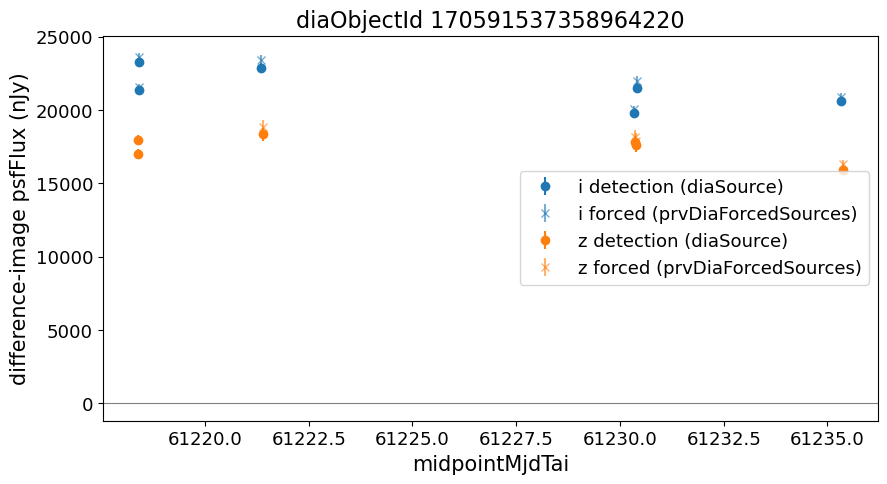

In [17]:
detections = alerts["diaSource"].nest.to_flat()
forced = alerts.iloc[-1]["prvDiaForcedSources"]

fig, ax = plt.subplots(figsize=(10, 5))
for i, band in enumerate(sorted(set(detections["band"]) | set(forced["band"]))):
    color = f"C{i}"
    det = detections[detections["band"] == band]
    ax.errorbar(
        det["midpointMjdTai"],
        det["psfFlux"],
        yerr=det["psfFluxErr"],
        fmt="o",
        color=color,
        label=f"{band} detection (diaSource)",
    )
    frc = forced[forced["band"] == band]
    ax.errorbar(
        frc["midpointMjdTai"],
        frc["psfFlux"],
        yerr=frc["psfFluxErr"],
        fmt="x",
        color=color,
        alpha=0.6,
        label=f"{band} forced (prvDiaForcedSources)",
    )
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("midpointMjdTai")
ax.set_ylabel("difference-image psfFlux (nJy)")
ax.set_title(f"diaObjectId {example_id}")
ax.legend()
plt.show()

## Selecting columns

Because there are no default columns, it pays to say what you need. Pass `columns=` to
`open_catalog`, and use dot notation for sub-columns of a nested column. `ra` and `dec` are always
included.

In [18]:
selected = lsdb.open_catalog(
    ALERT_ARCHIVE_PATH,
    columns=["diaSourceId", "diaSource.midpointMjdTai", "diaSource.band", "diaSource.psfFlux"],
)
selected_partition = selected.get_partition(pixel.order, pixel.pixel).compute()
selected_partition.head(3)

Building task graph...


Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

diaSourceId          ra        dec  \
_healpix_29                                                      
1196673254757203164  170648703094752653  351.913044 -17.913482   
1196673254757964556  170604727749312649  351.913035 -17.913421   
1196677393259435555  170648703116771388  352.219583 -17.938461   

                                                             diaSource  
_healpix_29                                                             
1196673254757203164  [{midpointMjdTai: 61231.413295, band: 'i', psf...  
1196673254757964556  [{midpointMjdTai: 61221.359076, band: 'i', psf...  
1196677393259435555  [{midpointMjdTai: 61231.413295, band: 'i', psf...

In [19]:
def megabytes(df):
    """In-memory size of a DataFrame in MB, including nested columns."""
    return df.memory_usage(deep=True).sum() / 1e6


print(f"all columns:      {megabytes(partition):6.1f} MB")
print(f"selected columns: {megabytes(selected_partition):6.1f} MB")

all columns:       134.5 MB
selected columns:    8.1 MB


The selection loads a small fraction of the data for the same partition. Across all of the
catalog's partitions, that difference largely determines how long a full-catalog query takes and
how much memory it needs.